# Лабораторная работа №2. Классификация состояний спутниковой подсистемы инструментами TensorFlow

**Тема:** классификация состояний спутниковых подсистем (норма / неисправность) по телеметрии.
**Что изучаем:** слои `Dense` и `Dropout`, обучение в Keras, балансировку классов, метрики accuracy, precision, recall, F1 и ROC-AUC.
**Данные:** SMAP (TsFile) — телеметрия спутника NASA SMAP, 25 каналов, метка аномалии для каждого момента времени ([THULab/SMAP на Hugging Face](https://huggingface.co/datasets/THULab/SMAP), лицензия CC BY 4.0).

## Команда и распределение задач

Каждая участница отвечает за свой раздел ноутбука. Имя стоит в заголовке раздела и в первой строке кода.

| Участница | **Задача** | Раздел ноутбука |
|---|---|---|
| Толмачева | **Данные и лицензия** | 2 |
| Гарбузова | **Состав набора** | 3 |
| Бурова | **Предобработка** | 4 |
| Монахова | **Разбиение выборки** | 5 |
| Лукавенко | **Архитектура сети** | 6 |
| Гребенец | **Обучение** | 7 |
| Цыхоня | **Метрики** | 8 |
| Попова | **Графики** | 9 |
| Шмидт | **Разбор ошибок** | 10 |
| Ерцкина | **README и сдача** | 11, 12 |

## Содержание
1. Теория
2. Данные и лицензия
3. Состав набора
4. Предобработка
5. Разбиение выборки
6. Архитектура сети
7. Обучение
8. Метрики
9. Графики
10. Разбор ошибок
11. Выводы
12. Ответы на контрольные вопросы

## 1. Теория

### 1.1. Какую задачу решаем
Спутник постоянно передаёт на Землю **телеметрию** — показания датчиков и отметки о поданных командах. Почти всё время подсистемы работают штатно, но иногда в показаниях появляется **аномалия**: сбой, отказ, необычный режим. Человек не может круглосуточно просматривать сотни тысяч чисел, поэтому нужна модель, которая по куску телеметрии сама скажет, норма это или неисправность.

Ответ здесь — один из двух классов: **0 — норма**, **1 — неисправность**. Это **бинарная классификация**. Если бы классов было больше (норма, перегрев, сбой питания…), задача была бы **многоклассовой**.

Классификация отличается от **регрессии** видом ответа. В регрессии ответ — число на непрерывной шкале (как остаточный ресурс батареи в ЛР1), в классификации — метка класса. От этого зависят выходной слой, функция потерь и метрики:

| | Регрессия (ЛР1) | Классификация (ЛР2) |
|---|---|---|
| Ответ | число | класс 0 или 1 |
| Выходной слой | linear | sigmoid |
| Функция потерь | MSE | бинарная кросс-энтропия |
| Метрики | MAE, RMSE | accuracy, precision, recall, F1, ROC-AUC |

### 1.2. Обучение с учителем
Модели показывают много примеров, у которых **известен правильный ответ**, и она подбирает свои внутренние числа так, чтобы отвечать правильно.

* **Признаки (X)** — то, что подаём на вход: числа, описывающие кусок телеметрии.
* **Метка (y)** — правильный ответ: 0 или 1.
* **Модель** — формула с настраиваемыми числами (**весами**), которая превращает X в ответ.

Данные делят на три части:
* **train** — на нём модель учится;
* **validation** — на нём следят за обучением и выбирают настройки (когда остановиться, какой порог), но не учатся;
* **test** — «экзамен», на который смотрят один раз в конце. По нему судят о качестве.

### 1.3. Из временного ряда — в таблицу
Телеметрия — **временной ряд**: измерения идут одно за другим. Полносвязная сеть работает с **таблицей**: строка — пример, столбец — признак. Чтобы перейти от ряда к таблице, ряд режут на **окна** — короткие куски по 50 отсчётов — и описывают каждое окно несколькими числами: средним, разбросом, минимумом, максимумом, изменением за окно, средним скачком. Одно окно — одна строка таблицы.

Зачем окна, а не отдельные строки: одно мгновение почти ничего не говорит, а неисправность видна в **поведении** сигнала — рост, дрожание, провал.

**Метка окна** — 1, если внутри есть хотя бы один аномальный отсчёт. Окна идут с шагом 10, поэтому соседние окна перекрываются на 80% и почти одинаковы. Это важно для разбиения (1.10).

### 1.4. Нейрон и полносвязный слой
**Нейрон** берёт входные числа, умножает каждое на свой вес, складывает, добавляет смещение $b$ и пропускает результат через **функцию активации** $f$:

$$ y = f\big(w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b\big) $$

**Слой Dense (полносвязный)** — набор нейронов, где каждый нейрон смотрит на **все** входы. Если на входе $n_{in}$ чисел, а в слое $n_{out}$ нейронов, у слоя $n_{in} \cdot n_{out} + n_{out}$ параметров: веса плюс по одному смещению на нейрон.

Сеть — несколько слоёв подряд. Первый слой находит простые сочетания признаков, следующие — сочетания этих сочетаний. Аналогия: жюри из 64 экспертов смотрит на все показатели окна, каждый со своими приоритетами; следующее жюри смотрит уже на мнения первого и т. д., последний судья выносит вердикт.

### 1.5. Функции активации

| Активация | Формула | Где используем | Смысл |
|---|---|---|---|
| **ReLU** | $\max(0, z)$ | скрытые слои | отрицательное обнуляет, положительное пропускает |
| **Sigmoid** | $\dfrac{1}{1 + e^{-z}}$ | выход бинарной классификации | превращает любое число в вероятность от 0 до 1 |
| **Softmax** | $\dfrac{e^{z_k}}{\sum_j e^{z_j}}$ | выход многоклассовой задачи | делит вероятность между классами, сумма = 1 |

Без нелинейной активации сколько слоёв ни складывай, получится одна линейная формула — та же логистическая регрессия. ReLU даёт сети «изгибы», и она может описывать сложные границы между нормой и сбоем.

Классов два, поэтому на выходе **один** нейрон с сигмоидой: он выдаёт $p$ — вероятность неисправности, вероятность нормы равна $1 - p$.

### 1.6. Функция потерь: бинарная кросс-энтропия
Функция потерь — число, которое показывает, насколько модель ошибается. Обучение — это поиск весов, при которых она минимальна. Для двух классов используют **бинарную кросс-энтропию**:

$$ L = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i \ln p_i + (1 - y_i)\ln(1 - p_i)\Big] $$

Если окно аномальное ($y = 1$), а сеть уверенно сказала $p = 0{,}01$, штраф $-\ln 0{,}01 \approx 4{,}6$. Если сказала $p = 0{,}9$, штраф всего $\approx 0{,}1$. Кросс-энтропия особенно сильно наказывает **уверенные ошибки**.

### 1.7. Как сеть учится
* **Градиентный спуск.** Считаем, в какую сторону надо сдвинуть каждый вес, чтобы ошибка уменьшилась (это **градиент**), и делаем небольшой шаг в эту сторону. Как спуск с горы вслепую: ощупываем уклон и шагаем вниз.
* **Обратное распространение ошибки** — способ быстро посчитать градиенты для всех слоёв: ошибка на выходе «растекается» от последнего слоя к первому.
* **Adam** — улучшенный градиентный спуск: сам подбирает размер шага для каждого веса.
* **Батч** — порция примеров (у нас 32 окна), после которой делается один шаг обновления весов.
* **Эпоха** — один полный проход по всем обучающим примерам.

### 1.8. Переобучение, Dropout и ранняя остановка
**Переобучение** — сеть запоминает обучающие примеры вместе с их шумом и хуже работает на новых. На графиках это видно так: ошибка на train продолжает падать, а на validation начинает расти.

* **Dropout(0.3)** на каждом шаге обучения случайно выключает 30% нейронов слоя. Сеть не может полагаться на отдельных «любимчиков» и учит устойчивые закономерности. При предсказании Dropout отключён — работает вся сеть.
* **EarlyStopping** следит за ошибкой на validation. Если она несколько эпох подряд не улучшается, обучение останавливается, и сеть возвращает веса лучшей эпохи.

### 1.9. Стандартизация и утечка данных
Признаки разного масштаба: флаги команд — 0 или 1, сигнал — от −1 до 1, разброс — сотые доли. Сеть чувствительна к масштабу, поэтому каждый признак приводят к среднему 0 и разбросу 1:

$$ z = \frac{x - \mu}{\sigma} $$

**Утечка данных** — когда в обучение просачивается информация из теста. Тогда метрики выглядят лучше, чем модель есть на самом деле. Поэтому $\mu$ и $\sigma$ считают **только по train**, а validation и test пересчитывают той же меркой.

### 1.10. Разбиение для временных рядов
Перемешивать окна случайно нельзя: соседние окна почти одинаковы, и у экзаменационного окна почти всегда найдётся «близнец» в обучении. Модель сдаст экзамен, просто вспомнив ответ.

Поэтому ряд режут на **блоки** (у нас по 5 000 отсчётов), и каждый блок целиком попадает в одну часть. На краях блока оставляют зазор, чтобы окна соседних блоков не делили ни одной точки. `StratifiedGroupKFold` раскладывает блоки так, чтобы доля аномалий в частях была похожей: *Group* — блоки не делятся, *Stratified* — доли классов выровнены.

### 1.11. Дисбаланс классов и SMOTE
Аномальных окон около 13%. Если ничего не делать, сеть быстро поймёт, что выгодно всегда отвечать «норма»: accuracy будет высокой, а найдено не будет ничего. Способы борьбы:
* **веса классов** (`class_weight`): ошибка на редком классе штрафуется сильнее;
* **пересэмплирование**: размножить редкий класс или проредить частый;
* **SMOTE** — создать новые искусственные примеры редкого класса;
* подбор **порога** и метрики, честные к редкому классу.

**SMOTE** берёт аномальное окно $x$, одного из его ближайших аномальных соседей $x_{nn}$ и ставит новую точку на отрезке между ними:

$$ x_{new} = x + \lambda\,(x_{nn} - x), \qquad \lambda \in [0, 1] $$

SMOTE применяют **только к train**. На test модель должна проверяться на настоящих данных с настоящей долей аномалий.

### 1.12. Baseline
**Baseline** — простая модель, с которой сравнивают сеть. Мы берём **логистическую регрессию**: это один нейрон с сигмоидой и без скрытых слоёв, граница между классами у неё прямая. Если сеть не лучше неё, скрытые слои ничего не дали. Ещё один ориентир — ответ «всегда норма»: он показывает, сколько accuracy можно получить, вообще ничего не находя.

### 1.13. Метрики классификации
Любой ответ попадает в одну из четырёх клеток **матрицы ошибок**. Положительный класс — неисправность:

|  | Модель: «неисправность» | Модель: «норма» |
|---|---|---|
| **На деле неисправность** | **TP** — нашли | **FN** — пропустили |
| **На деле норма** | **FP** — ложная тревога | **TN** — верно «норма» |

* **Accuracy** $= \dfrac{TP + TN}{TP + TN + FP + FN}$ — доля верных ответов. При 87% нормы ответ «всегда норма» даёт 0,87 и при этом бесполезен.
* **Precision** $= \dfrac{TP}{TP + FP}$ — из всех тревог сколько настоящих. Низкая precision — много ложных тревог.
* **Recall** $= \dfrac{TP}{TP + FN}$ — из всех неисправностей сколько нашли. Низкий recall — пропускаем настоящие сбои; для спутника это обычно опаснее.
* **F1** $= \dfrac{2 \cdot P \cdot R}{P + R}$ — одно число, компромисс precision и recall.
* **ROC-AUC** — площадь под ROC-кривой (доля найденных сбоев против доли ложных тревог при всех порогах). Это вероятность того, что случайное аномальное окно получит больший балл, чем случайное нормальное: 0,5 — угадывание, 1 — идеал.
* **PR-AUC** — площадь под кривой precision–recall. Для редкого класса она строже ROC-AUC: её уровень случайного угадывания равен доле аномалий (около 0,13), а не 0,5.

### 1.14. Порог решения
Сеть выдаёт вероятность, а решение «неисправность / норма» принимают по **порогу**: обычно 0,5. Ниже порог — больше найденных сбоев (recall растёт), но и больше ложных тревог (precision падает). Порог можно подбирать, но **только на validation**: подбор на test — это подгонка под экзамен.

### 1.15. Оценка по участкам
Аномалия обычно длится не одно окно, а целый **участок**. Для оператора важно, заметила ли модель сам случай сбоя, а не каждое его окно. Участок считаем **найденным**, если тревога сработала хотя бы в одном его окне.

### Подготовка окружения

Подключаем библиотеки и фиксируем случайность, чтобы при каждом запуске получались одни и те же числа. `StratifiedGroupKFold` нужен для разбиения выборки блоками (раздел 5).

Сеть собирается в **Keras** — части TensorFlow для построения нейросетей. Импортируем его как `keras`: это тот же модуль, что `tf.keras`, но так его видит и редактор кода.

In [1]:
# Импорты и настройки запуска
import warnings
warnings.filterwarnings("ignore")   # не засоряем вывод служебными предупреждениями

import importlib                     # загрузка библиотеки по имени (для запасного чтения TsFile)
import random                        # стандартный генератор случайных чисел Python
from pathlib import Path             # удобная работа с путями к файлам

import numpy as np                   # массивы и математика
import pandas as pd                  # таблицы
import matplotlib.pyplot as plt      # графики
import seaborn as sns                # графики поверх matplotlib (countplot, heatmap)

from sklearn.model_selection import StratifiedGroupKFold   # разбиение целыми группами с похожей долей классов
from sklearn.preprocessing import StandardScaler           # приведение признаков к среднему 0 и разбросу 1
from sklearn.linear_model import LogisticRegression        # простая модель для сравнения
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, average_precision_score,
                             precision_recall_curve)       # метрики качества классификации
from imblearn.over_sampling import SMOTE                   # досоздание примеров редкого класса

import tensorflow as tf                           # библиотека нейросетей
import keras                                      # Keras: сборка и обучение сетей поверх TensorFlow
from keras.models import Sequential               # сеть как список слоёв
from keras.layers import Input, Dense, Dropout    # вход, полносвязный слой, выключение нейронов
from keras.callbacks import EarlyStopping         # ранняя остановка обучения

plt.rcParams["figure.figsize"] = (10, 4)   # размер графиков по умолчанию
pd.set_option("display.width", 160)        # таблицы печатаются в одну строку, без переносов

SEED = 42                                  # одно зерно случайности на всю работу
random.seed(SEED)                          # фиксируем случайность Python
np.random.seed(SEED)                       # фиксируем случайность NumPy
keras.utils.set_random_seed(SEED)          # фиксируем случайность TensorFlow (и заодно Python и NumPy)

DATA_DIR = Path("data")   # папка с данными рядом с ноутбуком
WINDOW = 50               # длина окна, отсчётов
STRIDE = 10               # шаг окна: следующее окно начинается на 10 отсчётов позже
BLOCK = 5000              # длина блока для разбиения, отсчётов
GAP = WINDOW              # зазор на краях блока: окна соседних блоков не пересекаются

print("TensorFlow", tf.__version__)   # проверка: какая версия TensorFlow загрузилась

TensorFlow 2.15.1


---
## 2. Данные и лицензия
**Ответственная: Толмачева**

В наборе два файла. `SMAP_train` содержит **только норму** (метка везде 0), классификатор на нём не обучить: он ни разу не увидит неисправность. Размеченный `SMAP_test` (метки 0/1 для каждого отсчёта) используем для обучения, валидации и теста, разрезав его на части.

| Пункт | Значение |
|---|---|
| Набор | SMAP (TsFile) |
| Публикация | [huggingface.co/datasets/THULab/SMAP](https://huggingface.co/datasets/THULab/SMAP), THULab (Tsinghua University) |
| Оригинал | подмножество `SMAP` из [thuml/Time-Series-Library](https://huggingface.co/datasets/thuml/Time-Series-Library) |
| Статья | Wu и др., *Deep Time Series Models: A Comprehensive Survey and Benchmark*, [arXiv:2407.13278](https://arxiv.org/abs/2407.13278) |
| Лицензия | **CC BY 4.0** |
| Наши изменения | признаки окон, стандартизация, разбиение блоками |

**CC BY 4.0** разрешает копировать, изменять и использовать данные, в том числе в учебных работах, при условии: указать авторов, дать ссылку на лицензию и отметить внесённые изменения.

Файлы TsFile читаются библиотекой `tsfile`. Чтобы ноутбук запускался без неё, данные уже сохранены в `data/cache/smap.npz`.

In [2]:
# Толмачева. Загрузка SMAP: из кэша или из файлов TsFile
def load_smap():
    cache = DATA_DIR / "cache" / "smap.npz"            # быстрый кэш с уже прочитанными данными
    if cache.exists():                                  # если кэш есть — берём из него
        z = np.load(cache, allow_pickle=True)
        return z["Xtr"], z["ytr"], z["Xte"], z["yte"], [str(c) for c in z["names"]]
    to_dataframe = importlib.import_module("tsfile").to_dataframe   # иначе читаем файлы TsFile (нужен pip install tsfile)
    out = []
    for name in ("SMAP_train.tsfile", "SMAP_test.tsfile"):
        df = to_dataframe(str(DATA_DIR / "raw" / name))                                    # файл -> таблица
        df = df.drop(columns=[c for c in df.columns if str(c).lower() in ("time", "timestamp")])  # время не признак
        label = [c for c in df.columns if str(c).lower().split(".")[-1] == "label"][0]     # столбец с меткой
        feats = df.drop(columns=[label]).select_dtypes("number")                           # 25 каналов
        out.append((feats.to_numpy(np.float32), df[label].to_numpy(int), list(feats.columns)))
    (Xtr, ytr, names), (Xte, yte, _) = out
    return Xtr, ytr, Xte, yte, names


Xtr_raw, ytr_raw, Xte_raw, yte_raw, CH_NAMES = load_smap()   # train: только норма; test: с метками 0/1
df = pd.DataFrame(Xte_raw, columns=CH_NAMES)                  # таблица из файла test: 25 каналов
df["fault"] = yte_raw                                         # целевой столбец: 0 — норма, 1 — неисправность

print(f"Файл train: {Xtr_raw.shape}, меток: {np.unique(ytr_raw)}")   # в train только метка 0
print(f"Размер данных (файл test): {df.shape}")                     # строки x (25 каналов + метка)
print(df.head())                                                    # первые 5 строк
print(f"\nРаспределение целевой переменной:\n{df['fault'].value_counts()}")   # сколько нормы и сбоев

Файл train: (135183, 25), меток: [0]
Размер данных (файл test): (427617, 26)
   channel_0  channel_1  channel_2  channel_3  channel_4  channel_5  channel_6  channel_7  channel_8  channel_9  ...  channel_16  channel_17  channel_18  \
0        1.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0  ...         0.0         0.0         0.0   
1        1.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0  ...         0.0         0.0         0.0   
2        1.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0  ...         0.0         0.0         0.0   
3        1.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0  ...         0.0         0.0         0.0   
4        1.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0        0.0  ...         0.0         0.0   

---
## 3. Состав набора
**Ответственная: Гарбузова**

Знакомимся с данными до обучения: сколько их, какие значения бывают у каналов, нет ли пропусков, как распределены классы и где лежат аномалии.

In [3]:
# Гарбузова. Статистики каналов, пропуски, аномальные участки
desc = df.describe().T[["mean", "std", "min", "max"]]               # среднее, разброс, минимум, максимум каждого столбца
desc["уникальных значений"] = [df[c].nunique() for c in df.columns]  # 2 значения = бинарный флаг
print(desc.round(3))
print(f"\nПропуски всего: {int(df.isnull().sum().sum())}")           # есть ли дыры в данных

starts = np.where(np.diff(np.r_[0, yte_raw]) == 1)[0]       # где метка меняется с 0 на 1 — начало участка
ends = np.where(np.diff(np.r_[yte_raw, 0]) == -1)[0] + 1    # где меняется с 1 на 0 — конец участка
lens = ends - starts                                        # длина каждого аномального участка
print(f"Аномальных участков: {len(starts)}, длина мин/медиана/макс: {lens.min()} / {int(np.median(lens))} / {lens.max()}")
print("Расстояние между началами соседних участков, медиана:", int(np.median(np.diff(starts))), "отсчётов")

             mean    std  min  max  уникальных значений
channel_0  -0.180  0.775 -1.0  1.0                54285
channel_1   0.019  0.137  0.0  1.0                    2
channel_2   0.003  0.059  0.0  1.0                    2
channel_3   0.015  0.123  0.0  1.0                    2
channel_4   0.000  0.018  0.0  1.0                    2
channel_5   0.090  0.286  0.0  1.0                    2
channel_6   0.069  0.253  0.0  1.0                    2
channel_7   0.001  0.026  0.0  1.0                    2
channel_8   0.000  0.014  0.0  1.0                    2
channel_9   0.000  0.018  0.0  1.0                    2
channel_10  0.000  0.002  0.0  1.0                    2
channel_11  0.001  0.025  0.0  1.0                    2
channel_12  0.000  0.012  0.0  1.0                    2
channel_13  0.000  0.020  0.0  1.0                    2
channel_14  0.000  0.020  0.0  1.0                    2
channel_15  0.000  0.008  0.0  1.0                    2
channel_16  0.000  0.008  0.0  1.0              

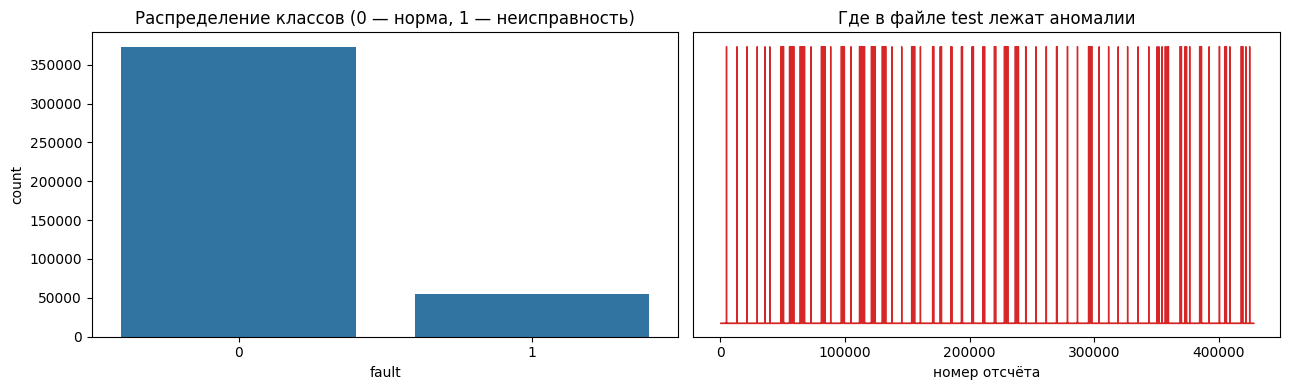

In [4]:
# Гарбузова. Баланс классов и положение аномалий в файле
fig, ax = plt.subplots(1, 2, figsize=(13, 4))                             # два графика рядом
sns.countplot(data=df, x="fault", ax=ax[0])                               # столбики: сколько нормы и сбоев
ax[0].set_title("Распределение классов (0 — норма, 1 — неисправность)")
ax[1].fill_between(np.arange(len(df)), yte_raw, step="mid", color="tab:red")   # красным — где метка 1
ax[1].set_title("Где в файле test лежат аномалии")
ax[1].set_xlabel("номер отсчёта"); ax[1].set_yticks([])
plt.tight_layout(); plt.show()

**Что видно.** Аномальны 12,8% отсчётов: классы несбалансированы. Пропусков нет. Непрерывный сигнал только один (`channel_0`), остальные 24 канала принимают значения 0 или 1 — это флаги команд.

Аномальные участки встречаются примерно каждые 6–8 тысяч отсчётов. Файл test в этой версии SMAP склеен из записей разных подсистем спутника, и почти в каждой записи один-два аномальных участка. Это важно для разбиения выборки (раздел 5).

**Постановка задачи.** Меток две (0 — норма, 1 — неисправность), других классов в наборе нет, поэтому задача бинарная.

---
## 4. Предобработка
**Ответственная: Бурова**

### 4.1. Пропуски

Пропусков нет, но шаг оставляем: если бы дыры были, `ffill().bfill()` заполнил бы их соседними значениями.

In [5]:
# Бурова. Заполнение пропусков соседними значениями
df = df.ffill().bfill()                                        # дыра -> предыдущее значение, в начале ряда -> следующее
print("Пропусков после обработки:", int(df.isnull().sum().sum()))
X_rows = df[CH_NAMES].to_numpy(np.float32)                     # сырые каналы, строка = один момент времени
y_rows = df["fault"].to_numpy(int)                             # метка каждого момента

Пропусков после обработки: 0


### 4.2. Признаки окна и целевая переменная

Одна строка телеметрии мало что говорит: неисправность видна в поведении сигнала за промежуток времени. Поэтому режем ряд на **окна** по 50 отсчётов с шагом 10. Для каждого канала окна считаем 6 чисел: среднее, разброс, минимум, максимум, изменение «конец минус начало» и среднее модуля скачка между соседними отсчётами. Получается 25 × 6 = 150 признаков на окно.

**Метка окна** (целевая переменная): 1, если внутри окна есть хотя бы один аномальный отсчёт, иначе 0. Метки уже числовые, кодировать их не нужно.

Окна режем внутри блоков по 5 000 отсчётов, отступив по 50 отсчётов от краёв блока. Так ни одно окно не пересекает границу блока, и окна из разных блоков не делят ни одной точки ряда.

*Сначала пробовали* пять статистик на канал, без среднего скачка, — 125 признаков, и резали окна по всему ряду подряд. Решили добавить средний скачок: он отличает «дёрганый» сигнал от ровного, даже когда среднее и разброс у них похожи. Нарезку внутри блоков сделали под разбиение из раздела 5.

In [6]:
# Бурова. Окна по 50 отсчётов, 6 статистик на канал, метка окна
STATS = ["mean", "std", "min", "max", "trend", "jump"]          # какие статистики считаем
FEAT_NAMES = [f"{s}_{c}" for s in STATS for c in CH_NAMES]      # имена 150 признаков, например mean_channel_0


def window_features(Xb, yb):
    st = np.arange(0, len(Xb) - WINDOW + 1, STRIDE)             # начала окон: 0, 10, 20, ...
    idx = st[:, None] + np.arange(WINDOW)[None, :]              # номера строк каждого окна, форма (окна, 50)
    w = Xb[idx]                                                 # сами окна, форма (окна, 50, 25 каналов)
    jump = np.abs(np.diff(w, axis=1)).mean(1)                   # средний модуль скачка между соседними отсчётами
    F = np.concatenate([w.mean(1), w.std(1), w.min(1), w.max(1), w[:, -1] - w[:, 0], jump], axis=1)   # 6 x 25 = 150
    return F.astype(np.float32), yb[idx].max(1), st             # признаки, метка окна (1, если есть сбой), начала


feats, labels, groups, win_start = [], [], [], []
for g, a in enumerate(range(0, len(X_rows), BLOCK)):           # идём по ряду блоками по 5000 строк, g — номер блока
    b = min(a + BLOCK, len(X_rows))                            # конец блока (последний может быть короче)
    a2, b2 = a + GAP, b - GAP                                  # отступаем по 50 строк от краёв блока
    if b2 - a2 < WINDOW:                                       # слишком короткий хвост — пропускаем
        continue
    F, L, st = window_features(X_rows[a2:b2], y_rows[a2:b2])  # окна только внутри блока
    feats.append(F); labels.append(L); groups.append(np.full(len(L), g)); win_start.append(st + a2)

X = np.concatenate(feats)               # все окна: (число окон, 150)
y = np.concatenate(labels)              # метка каждого окна
groups = np.concatenate(groups)         # номер блока каждого окна — понадобится для разбиения
win_start = np.concatenate(win_start)   # где в файле начинается окно — для разбора ошибок
print(f"Окон: {len(y)}, признаков: {X.shape[1]}, блоков: {len(np.unique(groups))}")
print(f"Доля аномальных окон: {y.mean():.3f}")

Окон: 41557, признаков: 150, блоков: 86
Доля аномальных окон: 0.135


---
## 5. Разбиение выборки
**Ответственная: Монахова**

### 5.1. Разбиение на train / validation / test

Перемешивать окна случайно нельзя: они идут с шагом 10 и перекрываются на 80%, соседние окна почти одинаковые. При случайном разбиении копия почти каждого тестового окна оказалась бы в обучении, и метрики были бы завышены.

Поэтому делим **блоками**: блок из 5 000 отсчётов целиком попадает в одну часть. `StratifiedGroupKFold` раскладывает блоки на 5 частей так, чтобы доля аномалий в частях была похожей. Одна часть — test, одна — validation, остальные три — train. Получается примерно 60/20/20.

Модель проверяется на отрезках времени, которых она не видела, но внутри тех же записей подсистем. Как она ведёт себя на совсем новых подсистемах, проверим отдельно в разделе 10.2.

*Сначала пробовали* резать файл по времени: первые 60% строк — train, следующие 20% — validation, последние 20% — test. Доли аномальных окон в частях вышли очень разными (16,9%, 5,9% и 11,1%), а модель на test угадывала хуже монетки: ROC-AUC 0,475. Логистическая регрессия на тех же признаках давала 0,74 на train и 0,39 на test, то есть дело было не в сети, а в разбиении: в test попадали записи подсистем, которых в обучении не было. Решили делить блоками, а разбиение по времени оставить как отдельную проверку в разделе 10.2.

In [7]:
# Монахова. Разбиение целыми блоками, доли аномалий в частях похожи
def group_split(seed):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)   # 5 частей, блоки не делятся
    folds = [te for _, te in sgkf.split(X, y, groups)]                          # номера окон каждой части
    test_idx, val_idx = folds[0], folds[1]                                      # 1 часть — test, 1 — validation
    train_idx = np.setdiff1d(np.arange(len(y)), np.r_[test_idx, val_idx])       # остальные 3 части — train
    return train_idx, val_idx, test_idx


train_idx, val_idx, test_idx = group_split(SEED)
assert not set(groups[train_idx]) & set(groups[test_idx])   # проверка: ни один блок не попал и в train, и в test
assert not set(groups[train_idx]) & set(groups[val_idx])    # ... и в train, и в validation
assert not set(groups[val_idx]) & set(groups[test_idx])     # ... и в validation, и в test

for name, idx in (("Train", train_idx), ("Val", val_idx), ("Test", test_idx)):
    print(f"{name:5s}: окон {len(idx):6d} ({len(idx) / len(y):.0%}), блоков {len(np.unique(groups[idx])):3d}, "
          f"аномальных окон {y[idx].mean():.1%}")

Train: окон  25272 (61%), блоков  52, аномальных окон 13.4%
Val  : окон   8023 (19%), блоков  17, аномальных окон 15.1%
Test : окон   8262 (20%), блоков  17, аномальных окон 12.4%


### 5.2. Нормализация признаков

`StandardScaler` приводит каждый признак к среднему 0 и разбросу 1. Масштаб считаем **только по train** и тем же масштабом преобразуем validation и test. Если посчитать его по всем данным сразу, в него попадёт информация из теста — это утечка.

*Сначала пробовали* масштабировать дважды: сырые строки, а потом ещё признаки окон. Решили оставить одно масштабирование признаков окон: результат тот же, а шагов меньше.

In [8]:
# Монахова. Стандартизация: масштаб считается только по train
scaler = StandardScaler().fit(X[train_idx])   # среднее и разброс каждого признака — только по train
scaler.scale_[scaler.scale_ < 1e-8] = 1.0     # константный признак: не делим на ноль

X_train, y_train = scaler.transform(X[train_idx]), y[train_idx]   # train в новой шкале
X_val, y_val = scaler.transform(X[val_idx]), y[val_idx]           # validation тем же масштабом
X_test, y_test = scaler.transform(X[test_idx]), y[test_idx]       # test тем же масштабом
print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")
print(f"Распределение классов в train:\n{pd.Series(y_train).value_counts()}")

Train: (25272, 150), Val: (8023, 150), Test: (8262, 150)
Распределение классов в train:
0    21890
1     3382
Name: count, dtype: int64


### 5.3. Балансировка классов: SMOTE

Аномальных окон в train около 13%. Без балансировки сети выгодно почти всегда отвечать «норма». **SMOTE** создаёт новые искусственные примеры редкого класса: берёт аномальное окно, одного из его ближайших аномальных соседей и ставит новую точку на отрезке между ними.

SMOTE применяем **только к train**. Validation и test остаются как есть: на них нужно мерить качество на настоящих данных с настоящим дисбалансом.

*Сначала пробовали* веса классов (`class_weight`): ошибка на аномалии стоила почти в 5 раз дороже ошибки на норме (2,957 против 0,602). Решили взять SMOTE: так сеть видит одинаковое число примеров обоих классов, а логистическая регрессия из раздела 8 учится на том же самом сбалансированном наборе, и сравнение моделей честное.

In [9]:
# Монахова. SMOTE только на train
smote = SMOTE(random_state=SEED)                                      # SMOTE с фиксированной случайностью
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)   # досоздаём аномальные окна
print(f"До SMOTE:\n{pd.Series(y_train).value_counts()}")
print(f"\nПосле SMOTE:\n{pd.Series(y_train_balanced).value_counts()}")

До SMOTE:
0    21890
1     3382
Name: count, dtype: int64

После SMOTE:
0    21890
1    21890
Name: count, dtype: int64


---
## 6. Архитектура сети
**Ответственная: Лукавенко**

Полносвязный перцептрон:

```
150 признаков → Dense(64, ReLU) → Dropout(0.3) → Dense(32, ReLU) → Dropout(0.3) → Dense(16, ReLU) → Dense(1, sigmoid)
```

* **Dense** — полносвязный слой: каждый нейрон смотрит на все входы.
* **ReLU** в скрытых слоях: отрицательное число превращает в 0, положительное пропускает.
* **Dropout(0.3)** на обучении случайно выключает 30% нейронов слоя, чтобы сеть не запоминала обучающие примеры. При предсказании он выключен.
* **Sigmoid** на выходе превращает число в вероятность аномалии от 0 до 1. Классов два, поэтому выход один.

Число весов у слоя Dense: входы × нейроны + нейроны (по одному смещению на нейрон). 150·64 + 64 = 9 664; 64·32 + 32 = 2 080; 32·16 + 16 = 528; 16·1 + 1 = 17. Всего **12 289**. У Dropout весов нет.

*Сначала пробовали* сеть короче: 125 → 64 → Dropout → 32 → Dropout → 1, без слоя на 16 нейронов, 10 177 весов. Там же сравнили её без Dropout и с Dropout 0,3: с Dropout PR-AUC на validation был немного выше (0,189 против 0,158), поэтому Dropout оставили. Решили добавить слой на 16 нейронов, чтобы сеть сужалась к выходу плавнее: 64 → 32 → 16 → 1.

In [10]:
# Лукавенко. Архитектура сети Dense + Dropout и компиляция
def build_model(n_features):
    model = Sequential([
        Input(shape=(n_features,)),        # вход: 150 признаков одного окна
        Dense(64, activation="relu"),      # 1-й скрытый слой: 64 нейрона
        Dropout(0.3),                      # на обучении выключаем 30% нейронов
        Dense(32, activation="relu"),      # 2-й скрытый слой: 32 нейрона
        Dropout(0.3),                      # снова выключаем 30%
        Dense(16, activation="relu"),      # 3-й скрытый слой: 16 нейронов
        Dense(1, activation="sigmoid"),    # выход: вероятность аномалии от 0 до 1
    ])
    model.compile(optimizer="adam",                                   # Adam сам подстраивает шаг для каждого веса
                  loss="binary_crossentropy",                         # функция потерь для двух классов
                  metrics=["accuracy",                                # доля верных ответов
                           keras.metrics.Precision(name="precision"),
                           keras.metrics.Recall(name="recall")])   # precision и recall при пороге 0.5
    return model


model = build_model(X_train.shape[1])   # собираем сеть под 150 признаков
model.summary()                         # таблица слоёв и число весов: должно быть 12 289

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 64)                9664      


 dropout (Dropout)           (None, 64)                0         


 dense_1 (Dense)             (None, 32)                2080      


... (3 outputs left out)

Total params: 12289 (48.00 KB)


Trainable params: 12289 (48.00 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


---
## 7. Обучение
**Ответственная: Гребенец**

* Оптимизатор **Adam**, функция потерь **binary_crossentropy** — стандарт для бинарной классификации.
* **EarlyStopping** следит за `val_loss`. Если 10 эпох подряд она не улучшается, обучение останавливается, и сеть возвращает веса лучшей эпохи (`restore_best_weights=True`).
* Учим на сбалансированном train порциями по 32 окна, качество по эпохам смотрим на validation.

*Сначала пробовали* останавливать обучение по PR-AUC на validation с терпением 6 эпох, уменьшать шаг обучения при застое (`ReduceLROnPlateau`), брать порции по 256 окон и не больше 40 эпох. Решили останавливать по `val_loss`: это та же величина, которую сеть минимизирует при обучении. Терпение увеличили до 10, потому что кривая на validation скачет и с 6 эпохами обучение могло оборваться слишком рано. Маленькие порции по 32 дают больше шагов обновления за эпоху, а без `ReduceLROnPlateau` обучение проще объяснить.

In [11]:
# Гребенец. Обучение на сбалансированном train с ранней остановкой
early_stop = EarlyStopping(monitor="val_loss",           # следим за ошибкой на validation
                           patience=10,                  # ждём 10 эпох без улучшения
                           restore_best_weights=True)    # в конце возвращаем веса лучшей эпохи

history = model.fit(
    X_train_balanced, y_train_balanced,     # учимся на сбалансированном train
    validation_data=(X_val, y_val),         # после каждой эпохи проверяем на validation
    epochs=100,                             # не больше 100 проходов по данным
    batch_size=32,                          # шаг обновления весов после каждых 32 окон
    callbacks=[early_stop],                 # ранняя остановка
    verbose=0,                              # не печатаем каждую эпоху
)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1   # эпоха с минимальной ошибкой на validation
print(f"Обучение остановлено на эпохе {len(history.history['loss'])}, лучшая эпоха по val_loss: {best_epoch}")

Обучение остановлено на эпохе 20, лучшая эпоха по val_loss: 10


---
## 8. Метрики
**Ответственная: Цыхоня**

### 8.1. Baseline: логистическая регрессия

Логистическая регрессия — линейная модель с сигмоидой на выходе. По сути это нейрон без скрытых слоёв. С ней сравниваем сеть: если сеть не лучше прямой границы, скрытые слои ничего не дали.

Для справки рядом ответ «всегда норма»: он показывает, сколько accuracy можно получить, вообще ничего не находя.

*Сначала пробовали* сравнивать сеть только с ответом «всегда норма». Решили добавить логистическую регрессию: «всегда норма» показывает лишь то, что accuracy обманчива, а понять, дают ли что-то скрытые слои, можно только рядом с обучаемой моделью попроще.

In [12]:
# Цыхоня. Baseline: логистическая регрессия и ответ «всегда норма»
def scores(y_true, y_pred, y_proba=None):
    out = {"Accuracy": accuracy_score(y_true, y_pred),                     # доля верных ответов
           "Precision": precision_score(y_true, y_pred, zero_division=0),   # доля настоящих среди тревог
           "Recall": recall_score(y_true, y_pred, zero_division=0),         # доля найденных среди сбоев
           "F1": f1_score(y_true, y_pred, zero_division=0)}                 # компромисс precision и recall
    if y_proba is not None:                                                 # если есть вероятности:
        out["ROC-AUC"] = roc_auc_score(y_true, y_proba)                     # качество ранжирования по всем порогам
        out["PR-AUC"] = average_precision_score(y_true, y_proba)            # то же, честнее для редкого класса
    return out


baseline = LogisticRegression(max_iter=1000)            # линейная модель, до 1000 шагов подбора весов
baseline.fit(X_train_balanced, y_train_balanced)        # учим на том же сбалансированном train, что и сеть

y_pred_baseline = baseline.predict(X_test)              # ответ 0/1 (порог 0.5)
y_proba_baseline = baseline.predict_proba(X_test)[:, 1] # вероятность аномалии

results = {"Всегда «норма»": scores(y_test, np.zeros_like(y_test)),                         # ответ «всегда 0»
           "Логистическая регрессия": scores(y_test, y_pred_baseline, y_proba_baseline)}
print("Baseline (Logistic Regression):")
for k, v in results["Логистическая регрессия"].items():
    print(f"  {k}: {v:.4f}")

Baseline (Logistic Regression):
  Accuracy: 0.4955
  Precision: 0.1837
  Recall: 0.8880
  F1: 0.3044
  ROC-AUC: 0.7121
  PR-AUC: 0.2384


### 8.2. Нейронная сеть на тестовой выборке

Сеть выдаёт вероятность аномалии. Окно считаем аномальным, если вероятность больше 0,5. Порог 0,5 — просто договорённость, поэтому дополнительно подбираем порог по максимуму F1 **на validation** и с ним один раз проверяем test. Подбирать порог на test нельзя: это была бы подгонка под экзамен.

*Сначала пробовали* брать итоговым порог, подобранный на validation (тогда он вышел 0,732). На test он резко снизил recall — с 0,541 до 0,067: модель почти перестала находить аномалии. Решили оставить итоговым порог 0,5, а подобранный показывать рядом для сравнения.

In [13]:
# Цыхоня. Метрики сети на test и порог, подобранный на validation
y_pred_proba = model.predict(X_test, verbose=0).flatten()   # вероятность аномалии для каждого тестового окна
y_pred = (y_pred_proba > 0.5).astype(int)                   # ответ сети при пороге 0.5

print("Нейронная сеть, порог 0.5:")
for k, v in scores(y_test, y_pred, y_pred_proba).items():
    print(f"  {k}: {v:.4f}")
print(f"\nClassification Report:\n{classification_report(y_test, y_pred, target_names=['норма', 'неисправность'], digits=3)}")

p_val = model.predict(X_val, verbose=0).flatten()                       # вероятности на validation
prec, rec, thr = precision_recall_curve(y_val, p_val)                   # precision и recall при всех порогах
f1_val = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)      # F1 при каждом пороге
THR = float(thr[np.argmax(f1_val)])                                     # порог с лучшим F1 на validation
y_pred_thr = (y_pred_proba > THR).astype(int)                           # ответ сети на test с этим порогом

results["Нейросеть, порог 0.5"] = scores(y_test, y_pred, y_pred_proba)
results[f"Нейросеть, порог {THR:.2f} (по val)"] = scores(y_test, y_pred_thr, y_pred_proba)
summary = pd.DataFrame(results).T                                       # сводная таблица всех моделей
print(f"Порог, подобранный на validation: {THR:.3f}\n")
print(summary.round(3))

Нейронная сеть, порог 0.5:
  Accuracy: 0.6765
  Precision: 0.2071
  Recall: 0.5667
  F1: 0.3034
  ROC-AUC: 0.7330
  PR-AUC: 0.3772

Classification Report:
               precision    recall  f1-score   support

        норма      0.918     0.692     0.789      7235
неисправность      0.207     0.567     0.303      1027

     accuracy                          0.676      8262
    macro avg      0.563     0.629     0.546      8262
 weighted avg      0.830     0.676     0.729      8262

Порог, подобранный на validation: 0.565

                                Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
Всегда «норма»                     0.876      0.000   0.000  0.000      NaN     NaN
Логистическая регрессия            0.496      0.184   0.888  0.304    0.712   0.238
Нейросеть, порог 0.5               0.676      0.207   0.567  0.303    0.733   0.377
Нейросеть, порог 0.56 (по val)     0.677      0.187   0.479  0.269    0.733   0.377


---
## 9. Графики
**Ответственная: Попова**

### 9.1. Кривые обучения

По горизонтали эпохи, по вертикали ошибка (слева) и accuracy (справа), отдельно для train и validation. Если обе кривые ошибки падают — сеть учится и обобщает. Если на train ошибка продолжает падать, а на validation растёт — началось переобучение. Пунктир — лучшая эпоха, к которой EarlyStopping вернул веса.

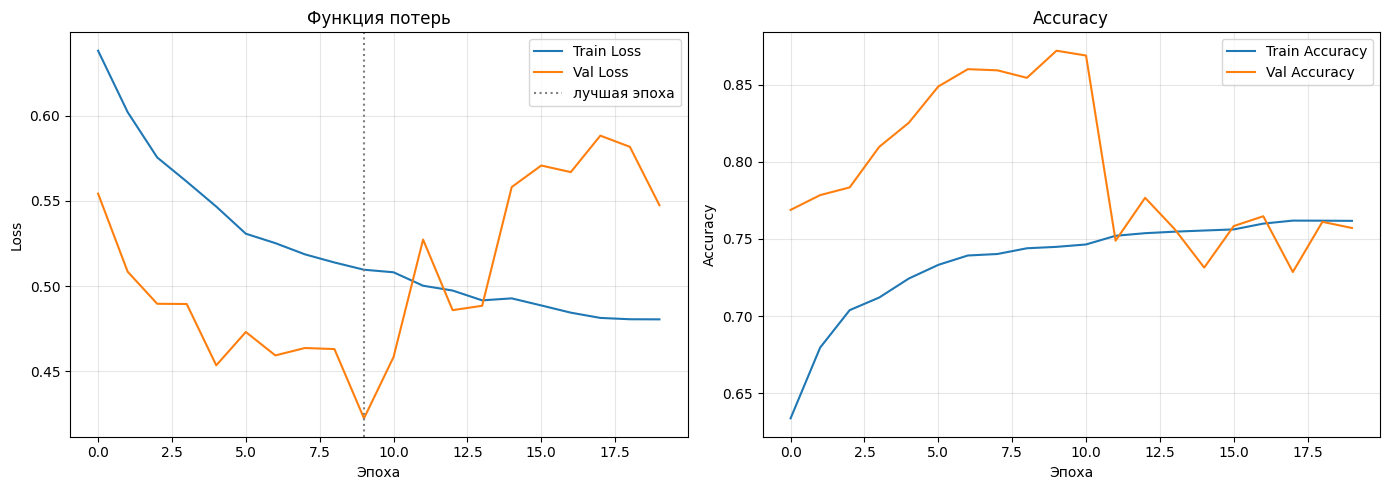

In [14]:
# Попова. Кривые loss и accuracy по эпохам
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                    # два графика рядом
axes[0].plot(history.history["loss"], label="Train Loss")           # ошибка на train по эпохам
axes[0].plot(history.history["val_loss"], label="Val Loss")         # ошибка на validation
axes[0].axvline(best_epoch - 1, color="gray", ls=":", label="лучшая эпоха")   # эпохи на оси считаются с 0
axes[0].set_title("Функция потерь"); axes[0].set_xlabel("Эпоха"); axes[0].set_ylabel("Loss")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history["accuracy"], label="Train Accuracy")   # доля верных ответов на train
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy") # и на validation
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Эпоха"); axes[1].set_ylabel("Accuracy")
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### 9.2. Матрица ошибок и ROC-кривая

Слева — четыре клетки TP / FN / FP / TN на test при пороге 0,5. Справа — ROC-кривые сети и логистической регрессии: чем ближе кривая к левому верхнему углу, тем лучше, красная диагональ — уровень случайного угадывания.

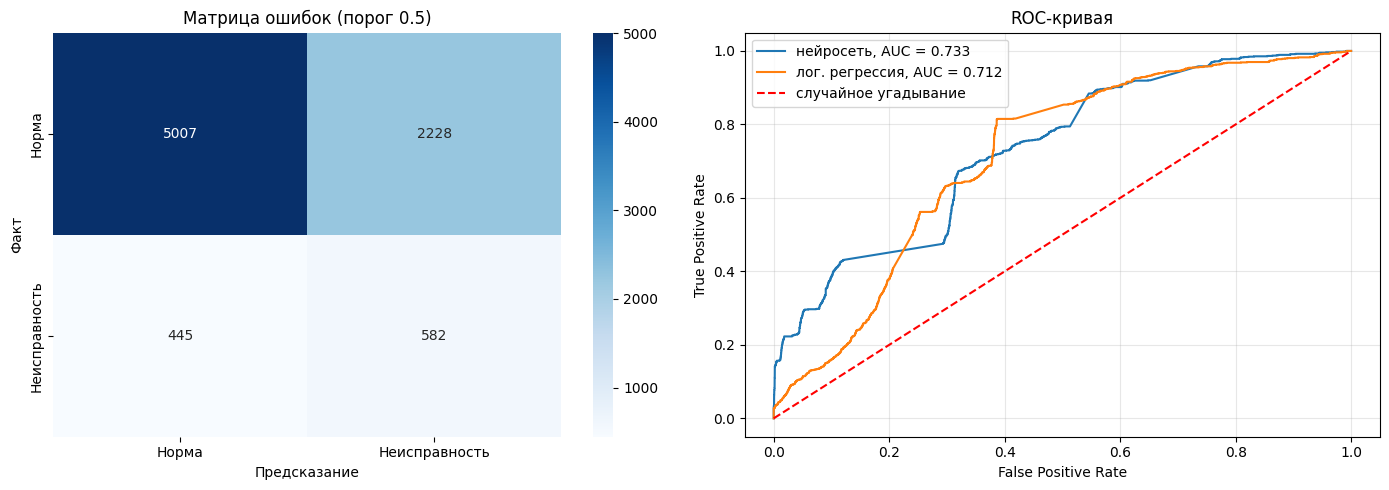

TP=582  FN=445  FP=2228  TN=5007


In [15]:
# Попова. Матрица ошибок и ROC-кривые сети и логистической регрессии
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)                                   # таблица 2x2: факт x предсказание
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],          # рисуем её с числами в клетках
            xticklabels=["Норма", "Неисправность"], yticklabels=["Норма", "Неисправность"])
axes[0].set_title("Матрица ошибок (порог 0.5)")
axes[0].set_xlabel("Предсказание"); axes[0].set_ylabel("Факт")

fpr, tpr, _ = roc_curve(y_test, y_pred_proba)                           # ROC сети: доля ложных тревог и найденных сбоев
fpr_b, tpr_b, _ = roc_curve(y_test, y_proba_baseline)                   # ROC логистической регрессии
axes[1].plot(fpr, tpr, label=f"нейросеть, AUC = {roc_auc_score(y_test, y_pred_proba):.3f}")
axes[1].plot(fpr_b, tpr_b, label=f"лог. регрессия, AUC = {roc_auc_score(y_test, y_proba_baseline):.3f}")
axes[1].plot([0, 1], [0, 1], "r--", label="случайное угадывание")       # диагональ — уровень монетки
axes[1].set_title("ROC-кривая")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()                  # четыре клетки матрицы по отдельности
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}")

---
## 10. Разбор ошибок
**Ответственная: Шмидт**

### 10.1. Какие окна и участки путаются

Аномальный участок для оператора важнее отдельных окон: участок считаем **найденным**, если тревога сработала хотя бы на одном его окне.

In [16]:
# Шмидт. Сколько аномальных участков найдено, сколько ложных тревог
test_blocks = np.unique(groups[test_idx])          # блоки, попавшие в test
found, missed_len, found_len = 0, [], []
total = 0
for g in test_blocks:                               # участки считаем внутри каждого блока отдельно
    m = groups[test_idx] == g                       # окна этого блока
    order = np.argsort(win_start[test_idx][m])      # по порядку во времени
    yt, yp = y_test[m][order], y_pred[m][order]     # истинные метки и ответы сети
    d = np.diff(np.r_[0, yt, 0])                    # +1 — начало участка, -1 — конец
    for a, b in zip(np.where(d == 1)[0], np.where(d == -1)[0]):
        total += 1
        if yp[a:b].any():                           # сработало хотя бы одно окно участка — найден
            found += 1; found_len.append(b - a)
        else:
            missed_len.append(b - a)
print(f"Аномальных участков в test: {total}, найдено: {found} ({found / total:.0%})")
if found_len:
    print(f"Средняя длина найденных: {np.mean(found_len):.1f} окон")
if missed_len:
    print(f"Средняя длина пропущенных: {np.mean(missed_len):.1f} окон")
print(f"\nЛожных тревог на 100 нормальных окон: {100 * fp / (fp + tn):.1f}")
print(f"Пропущено аномальных окон: {fn} из {fn + tp}")

Аномальных участков в test: 16, найдено: 14 (88%)
Средняя длина найденных: 71.9 окон
Средняя длина пропущенных: 10.0 окон

Ложных тревог на 100 нормальных окон: 30.8
Пропущено аномальных окон: 445 из 1027


### 10.2. Устойчивость результата и проверка на новых подсистемах

Одно разбиение может оказаться удачным или неудачным. Поэтому весь путь — масштабирование, SMOTE, логистическая регрессия и сеть — повторяем ещё на трёх случайных раскладках блоков.

Последняя строка — **разбиение по времени**: первые 60% блоков в train, следующие 20% в validation, последние 20% в test. Так в тест попадают записи подсистем, которых в обучении не было совсем.

In [17]:
# Шмидт. Повтор всего пути на других разбиениях и проверка по времени
def run_pipeline(tr, va, te, seed):
    keras.utils.set_random_seed(seed)                                               # своя случайность для прогона
    sc = StandardScaler().fit(X[tr]); sc.scale_[sc.scale_ < 1e-8] = 1.0            # масштаб только по train
    Xtr, Xva, Xte = sc.transform(X[tr]), sc.transform(X[va]), sc.transform(X[te])
    Xb, yb = SMOTE(random_state=seed).fit_resample(Xtr, y[tr])                      # SMOTE только на train
    p_lr = LogisticRegression(max_iter=1000).fit(Xb, yb).predict_proba(Xte)[:, 1]   # логистическая регрессия
    m = build_model(Xtr.shape[1])                                                   # та же сеть с нуля
    m.fit(Xb, yb, validation_data=(Xva, y[va]), epochs=100, batch_size=32,
          callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)], verbose=0)
    p_nn = m.predict(Xte, verbose=0).flatten()                                      # вероятности сети на test
    return {"доля аномалий в test": y[te].mean(),
            "ROC-AUC лог. регрессии": roc_auc_score(y[te], p_lr),
            "ROC-AUC сети": roc_auc_score(y[te], p_nn),
            "PR-AUC сети": average_precision_score(y[te], p_nn),
            "F1 сети (порог 0.5)": f1_score(y[te], (p_nn > 0.5).astype(int))}


rows = {f"блоки, раскладка {SEED} (основная)": {          # основной результат уже посчитан выше
    "доля аномалий в test": y_test.mean(),
    "ROC-AUC лог. регрессии": roc_auc_score(y_test, y_proba_baseline),
    "ROC-AUC сети": roc_auc_score(y_test, y_pred_proba),
    "PR-AUC сети": average_precision_score(y_test, y_pred_proba),
    "F1 сети (порог 0.5)": f1_score(y_test, y_pred)}}
for s in (0, 1, 2):                                          # ещё три раскладки блоков
    rows[f"блоки, раскладка {s}"] = run_pipeline(*group_split(s), s)

blocks = np.unique(groups)                                                  # номера блоков по порядку во времени
b1, b2 = blocks[int(len(blocks) * 0.6)], blocks[int(len(blocks) * 0.8)]     # границы 60% и 80%
chrono = (np.where(groups < b1)[0],                                         # первые 60% блоков — train
          np.where((groups >= b1) & (groups < b2))[0],                      # следующие 20% — validation
          np.where(groups >= b2)[0])                                        # последние 20% — test
rows["по времени: новые подсистемы"] = run_pipeline(*chrono, SEED)

robust = pd.DataFrame(rows).T
print(robust.round(3))

                                доля аномалий в test  ROC-AUC лог. регрессии  ROC-AUC сети  PR-AUC сети  F1 сети (порог 0.5)
блоки, раскладка 42 (основная)                 0.124                   0.712         0.733        0.377                0.303
блоки, раскладка 0                             0.138                   0.658         0.726        0.315                0.385
блоки, раскладка 1                             0.206                   0.510         0.618        0.253                0.293
блоки, раскладка 2                             0.258                   0.571         0.715        0.504                0.470
по времени: новые подсистемы                   0.105                   0.409         0.377        0.085                0.112


---
## 11. Выводы
**Ответственная: Ерцкина**

**Какая архитектура использовалась.** Полносвязная сеть: 150 признаков окна → Dense(64, ReLU) → Dropout(0,3) → Dense(32, ReLU) → Dropout(0,3) → Dense(16, ReLU) → Dense(1, sigmoid), всего 12 289 параметров. Оптимизатор Adam, функция потерь binary_crossentropy. EarlyStopping остановил обучение на 20-й эпохе и вернул веса лучшей, 10-й.

**Какие метрики достигнуты.** На test при пороге 0,5:

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|---:|
| Всегда «норма» | 0,876 | 0 | 0 | 0 | — | — |
| Логистическая регрессия | 0,496 | 0,184 | 0,888 | 0,304 | 0,712 | 0,238 |
| Нейронная сеть | 0,676 | 0,207 | 0,567 | 0,303 | 0,733 | 0,377 |

Сеть лучше логистической регрессии отделяет аномалии от нормы: ROC-AUC 0,733 против 0,712, PR-AUC 0,377 против 0,238. F1 при пороге 0,5 у них одинаковый, но получен по-разному. Регрессия ловит 89% аномальных окон ценой огромного числа ложных тревог (accuracy 0,50). Сеть ловит 57% окон и ошибается заметно реже (accuracy 0,68). Ответ «всегда норма» даёт самую высокую accuracy, 0,876, но не находит ни одной неисправности, поэтому accuracy здесь — плохая мера.

Порог, подобранный на validation (0,56), на test дал F1 хуже, чем порог 0,5 (0,269 против 0,303): доля и вид аномалий в разных блоках отличаются, и порог не переносится. Итоговым оставлен порог 0,5.

**Как обработали дисбаланс классов.** SMOTE применён только к train: аномальных окон стало столько же, сколько нормальных (по 21 890). Validation и test не трогали, чтобы мерить качество на реальном дисбалансе. Утечку закрыли ещё двумя мерами: стандартизация обучена только на train, а выборка разбита целыми блоками, поэтому перекрывающиеся окна не попадают в разные части.

**Какие классы путаются чаще всего.** Чаще всего сеть принимает норму за неисправность: 2 228 ложных тревог против 445 пропущенных аномальных окон. На уровне участков найдено 14 аномалий из 16. Пропущенные участки короткие, в среднем около 10 окон против 72 у найденных.

**Устойчивость и ограничение.** На четырёх разных раскладках блоков ROC-AUC сети 0,62–0,73, логистической регрессии 0,51–0,71: сеть каждый раз не хуже. Если разбить данные по времени, в тест попадают записи подсистем, которых не было в обучении, и обе модели оказываются ниже случайного угадывания (ROC-AUC 0,38 и 0,41). Классификатор выучивает признаки неисправностей конкретных подсистем и на новые их не переносит. Для новых подсистем лучше подходит модель, обученная только на норме, — автоэнкодер из ЛР5.

## 12. Ответы на контрольные вопросы
**Ответственная: Ерцкина**

**1. Чем задача классификации отличается от задачи регрессии?**
В классификации ответ — класс из заранее известного набора: здесь «норма» или «неисправность». В регрессии ответ — число на непрерывной шкале, например остаточный ресурс батареи в циклах в ЛР1. Поэтому различаются выходной слой (сигмоида или softmax против линейного выхода), функция потерь (кросс-энтропия против MSE) и метрики (accuracy, precision, recall против MAE, RMSE).

**2. Почему для бинарной классификации используется сигмоида, а для многоклассовой — softmax?**
Сигмоида превращает одно число в вероятность от 0 до 1, вероятность второго класса — это единица минус она. Для двух классов хватает одного выходного нейрона. Softmax берёт по числу на каждый класс и делит вероятность между всеми классами так, чтобы сумма была 1. Это нужно, когда классов больше двух и объект относится ровно к одному из них.

**3. Что такое матрица ошибок и как её интерпретировать?**
Это таблица 2×2: по строкам истинный класс, по столбцам предсказанный. На диагонали верные ответы: TN (норма названа нормой) и TP (неисправность найдена). Вне диагонали ошибки: FP — ложная тревога, FN — пропущенная неисправность. В этой работе FP = 2 228, FN = 445, значит, сеть чаще поднимает ложную тревогу, чем пропускает аномалию.

**4. В чём разница между precision и recall? Когда какой показатель важнее?**
Precision = TP / (TP + FP) — какая доля тревог настоящая. Recall = TP / (TP + FN) — какую долю реальных неисправностей нашли. Для спутника обычно важнее recall: пропущенная неисправность опаснее лишней проверки. Precision важнее, когда каждая тревога дорогая: например, если из-за неё отключают аппаратуру или отвлекают дежурного оператора.

**5. Что такое дисбаланс классов и какие методы борьбы с ним существуют?**
Дисбаланс — когда одного класса намного меньше, здесь около 13% аномальных окон. Модель тогда может просто всегда отвечать «норма». Методы: пересэмплирование (SMOTE или дублирование редкого класса, удаление части частого), веса классов в функции потерь (`class_weight`), подбор порога решения и метрики, честные к редкому классу (precision, recall, F1, PR-AUC).

**6. Как работает SMOTE и почему его нельзя применять к тестовой выборке?**
SMOTE берёт пример редкого класса, находит его ближайших соседей того же класса и создаёт новые точки на отрезках между ними. Это искусственные данные. На тесте модель должна проверяться на настоящих наблюдениях с настоящей долей аномалий. Если применить SMOTE к тесту, метрики будут посчитаны на выдуманных примерах и с неверным дисбалансом. Поэтому SMOTE применяется только к train, уже после разбиения.

**7. Что такое ROC-AUC и как интерпретировать этот показатель?**
ROC-кривая показывает, как растёт доля найденных неисправностей (TPR) вместе с долей ложных тревог (FPR), когда порог меняется от 1 до 0. AUC — площадь под этой кривой. Её можно понимать как вероятность того, что случайное аномальное окно получит от модели больший балл, чем случайное нормальное. 0,5 — угадывание, 1 — идеал, меньше 0,5 — хуже угадывания. У сети ROC-AUC 0,733.

**8. Почему accuracy не всегда является хорошей метрикой для несбалансированных данных?**
Accuracy считает все правильные ответы вместе, а нормальных окон гораздо больше. Ответ «всегда норма» в этой работе даёт accuracy 0,876, выше, чем у сети (0,676), хотя не находит ни одной неисправности. Поэтому для редкого класса смотрят recall, precision, F1 и PR-AUC.

**9. Какие функции потерь используются для бинарной и многоклассовой классификации?**
Для бинарной — бинарная кросс-энтропия (`binary_crossentropy`) в паре с сигмоидой на выходе. Для многоклассовой — категориальная кросс-энтропия: `categorical_crossentropy` для меток в виде one-hot или `sparse_categorical_crossentropy` для номеров классов, в паре с softmax. Кросс-энтропия сильно штрафует уверенный, но неверный ответ.

**10. Как интерпретировать графики обучения для задачи классификации?**
Если loss на train и на validation падают вместе, сеть учится и обобщает. Если train-loss продолжает падать, а val-loss начинает расти, началось переобучение — тогда помогают Dropout и EarlyStopping. В этой работе лучшая эпоха по val_loss — 10-я, после неё validation перестаёт улучшаться, и EarlyStopping вернул веса этой эпохи. Accuracy на дисбалансе читать нужно осторожно: она может расти просто потому, что сеть чаще отвечает «норма».